<a href="https://colab.research.google.com/github/JaveedRehman/brainllm/blob/main/neuro_qwen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NeuroQwen: Qwen 4-bit with a neurotransmitter system

Six simulated chemicals (dopamine, serotonin, norepinephrine, acetylcholine, glutamate, GABA), each with a level where **1.0 = balance**.
Every generated token: **random noise** kicks each level, a **PID controller** pulls it back to balance, and opposing chemicals inhibit each other.
**Push prompts** (random, from the environment) and **pull prompts** (written by the controller to oppose the biggest deviation) also shift the state.

The 4-bit weights are never modified. The chemistry changes the computation through forward hooks and the sampling step.

**Setup:** Runtime > Change runtime type > T4 GPU, then Run all.

## 1. Install

In [1]:
!pip -q install -U transformers accelerate bitsandbytes matplotlib

## 2. Imports and model choice

In [2]:
import random
import torch
from transformers import (AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig,
                          LogitsProcessor, LogitsProcessorList)

MODEL = "Qwen/Qwen2.5-1.5B-Instruct"   # try 3B if the T4 has room

## 3. Neurochemistry: noise + PID homeostasis + push/pull prompt generator

In [3]:
NAMES = ["dopamine", "serotonin", "norepinephrine",
         "acetylcholine", "glutamate", "gaba"]


def clamp(x, lo, hi):
    return max(lo, min(hi, x))


class Neurochem:
    """Levels around setpoint 1.0 with noise + PID homeostasis + cross-talk."""

    def __init__(self, noise=0.02, kp=0.08, ki=0.004, kd=0.15,
                 kick_decay=0.7, seed=None):
        self.rng = random.Random(seed)
        self.noise, self.kp, self.ki, self.kd = noise, kp, ki, kd
        self.kick_decay = kick_decay
        self.sp = {n: 1.0 for n in NAMES}          # setpoints (balance)
        self.level = dict(self.sp)
        self.I = {n: 0.0 for n in NAMES}           # integral term
        self.prev = {n: 0.0 for n in NAMES}        # last error (derivative)
        self.kick = {n: 0.0 for n in NAMES}        # pending external pushes
        self.control_on = True                     # set False to watch it drift
        # target: [(source, strength)]  opposing systems inhibit each other
        self.coupling = {
            "glutamate": [("gaba", -0.10)], "gaba": [("glutamate", -0.10)],
            "dopamine": [("serotonin", -0.05)], "serotonin": [("dopamine", -0.05)],
        }
        self.history = []

    def d(self, n):                                # deviation from balance
        return self.level[n] - self.sp[n]

    def max_dev(self):
        n = max(NAMES, key=lambda k: abs(self.d(k)))
        return n, self.d(n)

    def impulse(self, effect):                     # a push from outside
        for n, v in effect.items():
            self.kick[n] += v

    def step(self):
        old = dict(self.level)
        for n in NAMES:
            err = self.sp[n] - old[n]
            self.I[n] = clamp(self.I[n] + err, -2.0, 2.0)       # anti-windup
            deriv = err - self.prev[n]
            self.prev[n] = err
            u = (self.kp * err + self.ki * self.I[n] + self.kd * deriv) if self.control_on else 0.0
            cross = sum(c * (old[s] - self.sp[s]) for s, c in self.coupling.get(n, []))
            eps = self.rng.gauss(0.0, self.noise)
            applied = self.kick[n]
            self.kick[n] *= self.kick_decay
            self.level[n] = clamp(old[n] + u + cross + eps + applied, 0.3, 1.9)
        self.history.append(dict(self.level))

    def reset(self):
        self.level = dict(self.sp)
        self.I = {n: 0.0 for n in NAMES}
        self.prev = {n: 0.0 for n in NAMES}
        self.kick = {n: 0.0 for n in NAMES}
        self.history = []


# ---- push / pull prompt generator ----------------------------------
UP = {
    "dopamine":       ["You feel driven and confident; commit to a bold answer.",
                       "You are excited about this and want to win."],
    "serotonin":      ["You feel calm, patient and content.",
                       "You are at peace and in no hurry."],
    "norepinephrine": ["You are on high alert; everything feels urgent.",
                       "Your senses are sharp and your heart is racing."],
    "acetylcholine":  ["Focus tightly on the exact words of the question.",
                       "Pay close, precise attention to every detail."],
    "glutamate":      ["Your mind is buzzing with ideas; say all of them.",
                       "Thoughts are firing fast and you can't hold them back."],
    "gaba":           ["Be careful and filter yourself; hold back anything risky.",
                       "You feel inhibited and cautious."],
}
DOWN = {
    "dopamine":       ["You feel flat and unmotivated; give a minimal answer.",
                       "Nothing seems worth the effort right now."],
    "serotonin":      ["You feel irritable and restless.",
                       "You are impatient and a bit on edge emotionally."],
    "norepinephrine": ["You are relaxed and a little drowsy.",
                       "Everything feels slow and quiet."],
    "acetylcholine":  ["Let your attention drift to loosely related ideas.",
                       "Your focus is hazy and wandering."],
    "glutamate":      ["Say only the bare essentials.",
                       "Your thoughts are sparse and quiet."],
    "gaba":           ["Your inhibitions are lowered; speak freely and loosely.",
                       "You feel uninhibited and unfiltered."],
}


class Stimulus:
    def __init__(self, kind, text, effect):
        self.kind, self.text, self.effect = kind, text, effect

    def __repr__(self):
        eff = ", ".join(f"{k}{v:+.2f}" for k, v in self.effect.items())
        return f"[{self.kind}] {self.text}  ({eff})"


class StimulusGenerator:
    def __init__(self, chem, strength=0.10, seed=None):
        self.chem, self.strength = chem, strength
        self.rng = random.Random(seed)

    def _make(self, kind, picks):
        parts, effect = [], {}
        for name, direction in picks:
            amp = self.strength * self.rng.uniform(0.6, 1.4)
            pool = UP[name] if direction > 0 else DOWN[name]
            parts.append(self.rng.choice(pool))
            effect[name] = direction * amp
        return Stimulus(kind, " ".join(parts), effect)

    def random_push(self):
        """Environment shoves 1-2 random chemicals in a random direction."""
        names = self.rng.sample(NAMES, self.rng.choice([1, 2]))
        return self._make("push", [(n, self.rng.choice([-1, 1])) for n in names])

    def pull_back(self):
        """Controller-made prompt that opposes the biggest deviation."""
        name, dev = self.chem.max_dev()
        return self._make("pull", [(name, -1 if dev > 0 else 1)])

## 4. Model loading, hooks and brain-driven sampler
Hook strengths are guesses. If output turns to gibberish, lower them; if nothing changes, raise them.

In [4]:
def load_model():
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                             bnb_4bit_compute_dtype=torch.float16,
                             bnb_4bit_use_double_quant=True)
    tok = AutoTokenizer.from_pretrained(MODEL)
    model = AutoModelForCausalLM.from_pretrained(
        MODEL, quantization_config=bnb, device_map="auto")
    model.eval()
    return tok, model


def attach_hooks(model, chem):
    """Chemistry changes the *computation*, not the quantized weights."""
    layers = model.model.layers
    n = len(layers)
    mid = range(n // 3, 2 * n // 3)

    def mlp_hook(module, inp, out):
        # glutamate excites, GABA inhibits the feed-forward output
        g = 1.0 + 0.6 * (chem.d("glutamate") - chem.d("gaba"))
        return out * clamp(g, 0.5, 1.6)

    def q_hook(module, inp, out):
        # acetylcholine = attention gain (scales attention logits)
        return out * clamp(chem.level["acetylcholine"], 0.6, 1.5)

    def noise_hook(module, inp, out):
        # norepinephrine = neural noise in the middle layers
        h = out[0] if isinstance(out, tuple) else out
        scale = h.abs().float().median(dim=-1, keepdim=True).values.to(h.dtype)
        sigma = 0.02 * chem.level["norepinephrine"]
        h2 = h + torch.randn_like(h) * sigma * scale
        return (h2,) + tuple(out[1:]) if isinstance(out, tuple) else h2

    handles = []
    for i, layer in enumerate(layers):
        handles.append(layer.mlp.register_forward_hook(mlp_hook))
        handles.append(layer.self_attn.q_proj.register_forward_hook(q_hook))
        if i in mid:
            handles.append(layer.register_forward_hook(noise_hook))
    return handles          # call h.remove() on each to restore plain Qwen


class BrainSampler(LogitsProcessor):
    """One call per token = one brain tick. Also shapes the sampling."""

    def __init__(self, chem, base_temp=0.8, base_top_p=0.92):
        self.chem, self.base_temp, self.base_top_p = chem, base_temp, base_top_p

    def __call__(self, input_ids, scores):
        c = self.chem
        c.step()
        s = scores.float()
        s = s * clamp(c.level["dopamine"], 0.5, 1.6)                 # drive / confidence
        s = s / (self.base_temp * clamp(c.level["norepinephrine"], 0.5, 1.8))  # arousal
        top_p = clamp(self.base_top_p - 0.25 * c.d("serotonin"), 0.5, 0.99)    # impulse control
        sl, idx = torch.sort(s, descending=True, dim=-1)
        probs = torch.softmax(sl, dim=-1)
        drop = (probs.cumsum(-1) - probs) > top_p
        sl = sl.masked_fill(drop, float("-inf"))
        return torch.full_like(s, float("-inf")).scatter(-1, idx, sl)

## 5. Agent loop and plotting

In [5]:
def make_agent(seed=None):
    tok, model = load_model()
    chem = Neurochem(seed=seed)
    gen = StimulusGenerator(chem, seed=seed)
    attach_hooks(model, chem)
    sampler = BrainSampler(chem)

    @torch.no_grad()
    def think(user, push_prob=0.6, pull_threshold=0.15, max_new_tokens=160, verbose=True):
        notes = []
        name, dev = chem.max_dev()
        if abs(dev) > pull_threshold:                 # controller writes a counter-prompt
            notes.append(gen.pull_back())
        elif random.random() < push_prob:             # environment pushes
            notes.append(gen.random_push())
        for s in notes:
            chem.impulse(s.effect)
        inner = " ".join(s.text for s in notes)
        system = "You are a helpful assistant." + (f" (Inner state: {inner})" if inner else "")
        msgs = [{"role": "system", "content": system},
                {"role": "user", "content": user}]
        ids = tok.apply_chat_template(msgs, add_generation_prompt=True,
                                      return_tensors="pt", return_dict=True).to(model.device)
        out = model.generate(**ids, max_new_tokens=max_new_tokens, do_sample=True,
                             temperature=1.0, top_p=1.0, top_k=0,
                             repetition_penalty=1.0,
                             logits_processor=LogitsProcessorList([sampler]))
        text = tok.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=True)
        if verbose:
            for s in notes:
                print(s)
            print({k: round(v, 2) for k, v in chem.level.items()})
            print("->", text, "\n")
        return text

    return tok, model, chem, gen, think


def plot_levels(chem):
    import matplotlib.pyplot as plt
    plt.figure(figsize=(10, 4))
    for n in NAMES:
        plt.plot([h[n] for h in chem.history], label=n)
    plt.axhline(1.0, ls="--", c="k", lw=0.8)
    plt.xlabel("token tick"); plt.ylabel("level (1.0 = balance)")
    plt.legend(ncol=3); plt.tight_layout(); plt.show()

## 6. Load Qwen and chat
Each turn prints the push/pull stimulus, the chemical levels, then the reply.

In [6]:
tok, model, chem, gen, think = make_agent(seed=0)

for q in ["Explain why the sky is blue.",
          "Give me a plan to study for my CFD exam.",
          "Write a short poem about rain in Kerala."]:
    think(q)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

[push] Pay close, precise attention to every detail. You are excited about this and want to win.  (acetylcholine+0.09, dopamine+0.14)
{'dopamine': 1.01, 'serotonin': 1.0, 'norepinephrine': 1.02, 'acetylcholine': 1.01, 'glutamate': 0.91, 'gaba': 1.11}
-> The sky appears blue because of the way sunlight interacts with the Earth's atmosphere. When sunlight travels through the atmosphere, it encounters the gases and particles present in the air. Some of the light scatters off of these particles and returns to our eyes, giving us the blue color we see. This is why the sky appears blue during the day, as it is the color that our eyes can detect the most from all other colors. At sunset, the sun is lower in the sky and is seen through the longer path of air between the sun and the eye. This path allows more blue light to be scattered, making the sky appear blue. 

[push] Say only the bare essentials.  (glutamate-0.08)
{'dopamine': 0.99, 'serotonin': 1.01, 'norepinephrine': 1.04, 'acetylcholin

## 7. Chemistry over time
Dashed line = balance. Pushes show as spikes, the controller pulls them back.

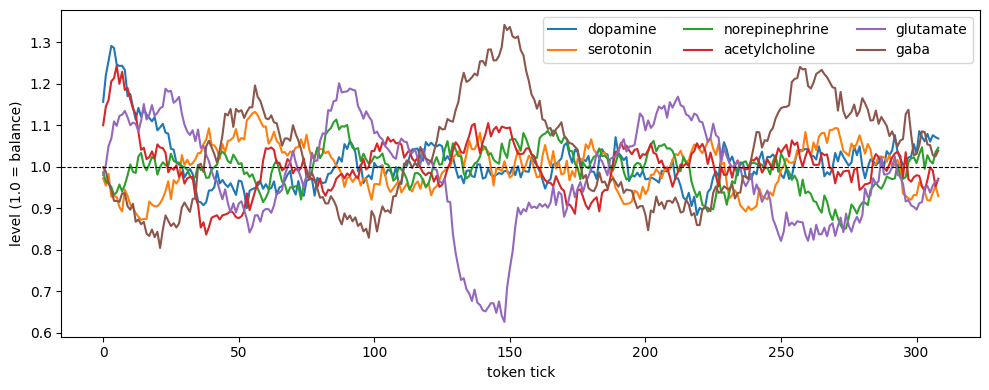

In [7]:
plot_levels(chem)

## 8. Ablations
Run one at a time, then ask the same questions again and compare. `chem.reset()` clears the state and history.

[push] Everything feels slow and quiet.  (norepinephrine-0.12)
{'dopamine': 0.85, 'serotonin': 1.1, 'norepinephrine': 0.84, 'acetylcholine': 1.01, 'glutamate': 1.9, 'gaba': 0.3}
-> When sunlight enters the Earth's atmosphere, it encounters the scattering effect of the air molecules. Blue light is scattered more than other colors of the visible light spectrum, so we perceive the sky as blue. 



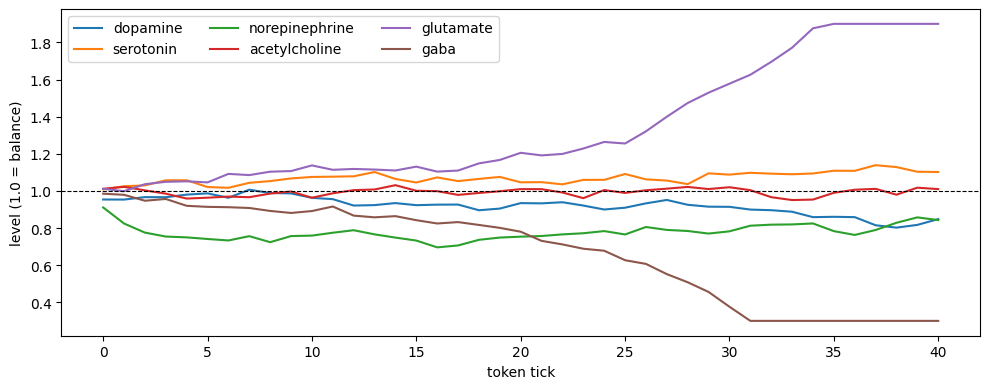

In [8]:
# A) no homeostasis: levels drift away from balance
chem.reset(); chem.control_on = False
think("Explain why the sky is blue.")
plot_levels(chem)

{'dopamine': 1.0, 'serotonin': 1.0, 'norepinephrine': 1.0, 'acetylcholine': 1.0, 'glutamate': 1.0, 'gaba': 1.0}
-> The sky appears blue because of the way our atmosphere scatters sunlight. Light from the sun travels through the Earth's atmosphere as a bundle of different colors, or wavelengths. These wavelengths are all mixed together and travel in all directions through the atmosphere. 

However, as light travels through the atmosphere, it is scattered by tiny particles such as water droplets in the clouds or air molecules. This scattering happens in all directions, and the light is scattered more strongly when it travels through the atmosphere.

When light scatters in all directions, we see it as blue light because it is scattered more strongly than other colors. Blue light has a shorter wavelength than other colors, so it is scattered more easily by the particles in the atmosphere. This is why the sky appears blue during the day. 



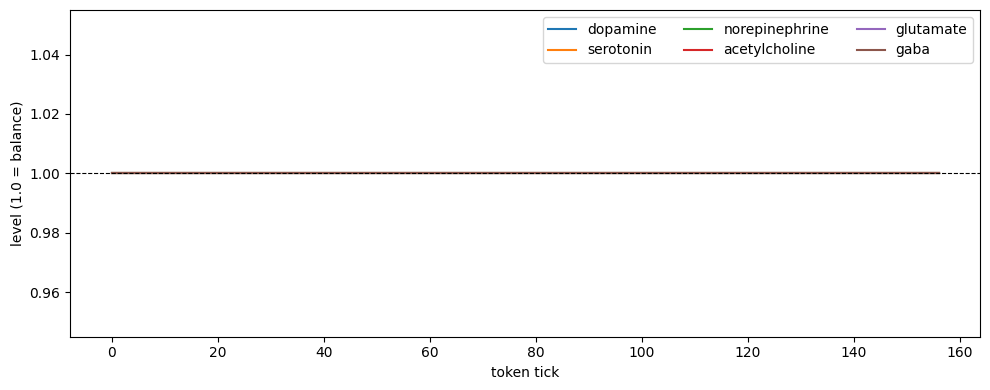

In [9]:
# B) no noise: smooth, deterministic chemistry
chem.reset(); chem.control_on = True; chem.noise = 0.0
think("Explain why the sky is blue.")
plot_levels(chem)

[push] Your mind is buzzing with ideas; say all of them. You are excited about this and want to win.  (glutamate+0.09, dopamine+0.14)
{'dopamine': 1.27, 'serotonin': 0.6, 'norepinephrine': 0.93, 'acetylcholine': 0.79, 'glutamate': 1.09, 'gaba': 0.63}
-> The sky appears blue to our eyes because of a phenomenon called Rayleigh scattering. When sunlight enters the Earth's atmosphere, its rays pass through millions of gas atoms and molecules, which scatter the light in all directions. Blue light, being scattered by these tiny air molecules more efficiently than other colors of the color spectrum, it gets scattered more, so we see it blue. 



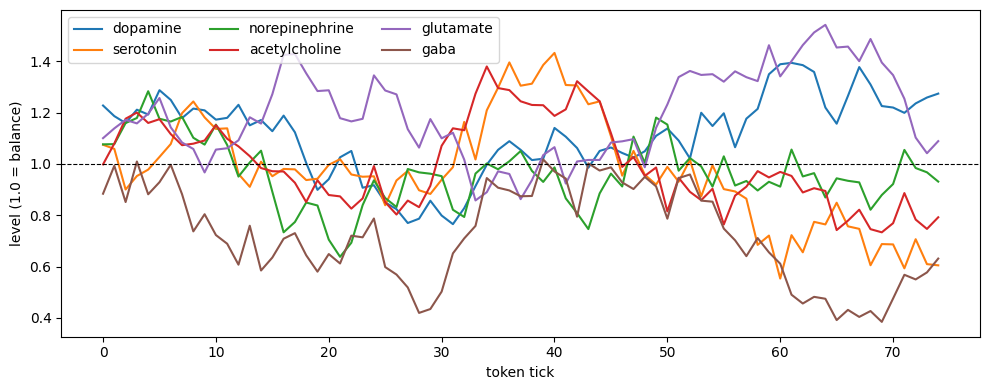

In [10]:
# C) high noise: unstable "mood"
chem.reset(); chem.noise = 0.08
think("Explain why the sky is blue.")
plot_levels(chem)

{'dopamine': 0.98, 'serotonin': 1.01, 'norepinephrine': 1.0, 'acetylcholine': 1.03, 'glutamate': 1.05, 'gaba': 0.89}
-> The father of the Malayalam language is Saint Thomas, who is believed to have brought the language to Kerala in the 1st century AD. The language is also known as Malayalam or Meitramal (the language of the monks). It is a Dravidian language and is spoken by about 30 million people in Kerala, Tamil Nadu, and other states. 



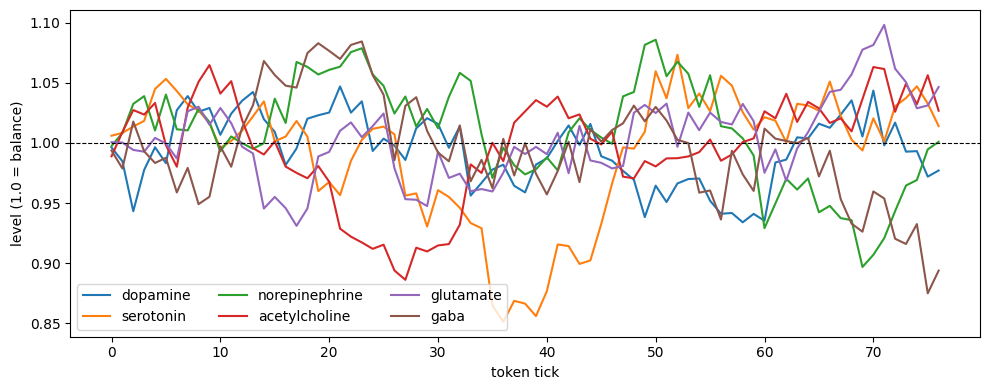

In [48]:
# Manual push/pull: shove one chemical yourself, watch the controller recover
chem.reset(); chem.noise = 0.02
chem.control_on = True
chem.impulse({"dopamine":0, "norepinephrine": 0, "gaba": 0, "glutamate":00, "serotonin":0, "acetylcholine":0,})
think("father of malayalam language", push_prob=0)
plot_levels(chem)